## Modeling

In [1]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from sklearn.metrics import roc_auc_score
from scipy.sparse import hstack

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

dim_artists = pd.read_csv('../../data/processed/to_db/dim_artists.csv')
dim_tracks = pd.read_csv('../../data/processed/to_db/dim_tracks.csv')
candidates = pd.read_csv('../../data/processed/clean_data/candidate_artists_lastfm.csv')

dataframes = [dim_artists, dim_tracks, candidates]
for i, dfs in enumerate(dataframes):
    print(f"Data {i + 1} - Missing: {(sum(dfs.isna().sum()) / len(dfs)) * 100}")
print("\n")

for i, dfs in enumerate(dataframes):
    print(f"Data {i + 1} - Duplicates: {dfs.duplicated().sum()}")

Data 1 - Missing: 2.866779089376054
Data 2 - Missing: 0.0
Data 3 - Missing: 10.587102983638113


Data 1 - Duplicates: 0
Data 2 - Duplicates: 0
Data 3 - Duplicates: 0


In [2]:
dim_artists.info()

<class 'pandas.DataFrame'>
RangeIndex: 593 entries, 0 to 592
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   artists_id           593 non-null    int64
 1   primary_artist_name  593 non-null    str  
 2   artist_listeners     593 non-null    int64
 3   artist_playcount     593 non-null    int64
 4   tags                 576 non-null    str  
 5   similar_artists      593 non-null    str  
 6   num_tags             593 non-null    int64
 7   num_similar_artists  593 non-null    int64
dtypes: int64(5), str(3)
memory usage: 240.1 KB


In [3]:
dim_tracks.info()

<class 'pandas.DataFrame'>
RangeIndex: 817 entries, 0 to 816
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   track_id      817 non-null    str    
 1   release_date  817 non-null    str    
 2   song_name     817 non-null    str    
 3   album_name    817 non-null    str    
 4   duration_min  817 non-null    float64
 5   artists_id    817 non-null    int64  
dtypes: float64(1), int64(1), str(4)
memory usage: 101.8 KB


In [4]:
candidates.info()

<class 'pandas.DataFrame'>
RangeIndex: 1039 entries, 0 to 1038
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   primary_artist_name  1039 non-null   str  
 1   artist_listeners     1039 non-null   int64
 2   artist_playcount     1039 non-null   int64
 3   tags                 943 non-null    str  
 4   similar_artists      1025 non-null   str  
dtypes: int64(2), str(3)
memory usage: 263.3 KB


In [5]:
norm = lambda s: s.str.lower().str.strip()
known = set(norm(dim_artists.primary_artist_name))

cand = candidates[~norm(candidates.primary_artist_name).isin(known)].dropna(subset=["tags"])
lib  = dim_artists.dropna(subset=["tags"])

cols = ["primary_artist_name", "artist_listeners", "artist_playcount", "tags", "similar_artists"]
all_artists = pd.concat([lib[cols].assign(source="library"),
                         cand[cols].assign(source="candidate")], ignore_index=True)

all_artists.head()

,primary_artist_name,artist_listeners,artist_playcount,tags,similar_artists,source
0,(Hed) P.E.,150657,4410090,"rapcore, Nu Metal, crossover, g-punk, alternat...","(hed) Planet Earth, Reveille, Primer 55, Coal ...",library
1,*NSYNC,2157048,32982790,"pop, boybands, 90s, dance, boy band, american,...","JC Chasez, Backstreet Boys, O-Town, Justin Tim...",library
2,2 Chainz,1490344,27551890,"Hip-Hop, rap, trap, Dirty South, southern rap,...","Young Jeezy, Lil' Wayne, Gucci Mane, T.I., Ric...",library
3,21 Savage,2407273,227824623,"trap, Hip-Hop, rap, hip hop, atlanta, british,...","Metro Boomin, Future, Offset, Travi$ Scott, Li...",library
4,2Pac,4312766,153016025,"rap, Hip-Hop, Gangsta Rap, West Coast Rap, hip...","Thug Life, The Notorious B.I.G., Dr. Dre, Snoo...",library


Text(0.5, 1.0, 'Song and Artist Sources')

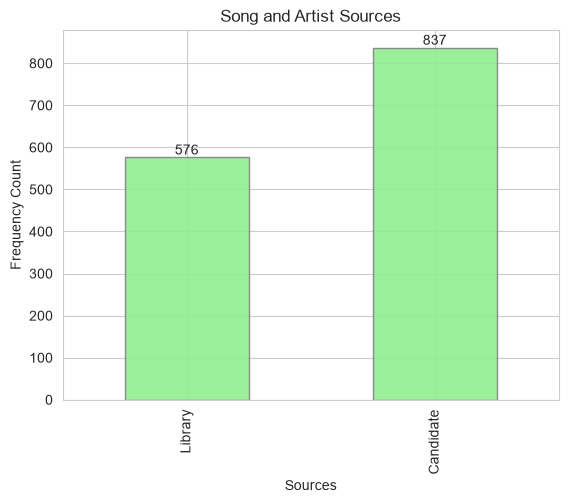

In [6]:
counts = all_artists['source'].value_counts().sort_values()

sns.set_style('whitegrid')
fig, ax = plt.subplots()

counts.plot(kind='bar', alpha=0.9, edgecolor='gray', color='lightgreen', ax=ax)
ax.set_xticklabels(labels=['Library', 'Candidate'])
ax.bar_label(ax.containers[0])
ax.set_xlabel('Sources')
ax.set_ylabel('Frequency Count')
ax.set_title('Song and Artist Sources')

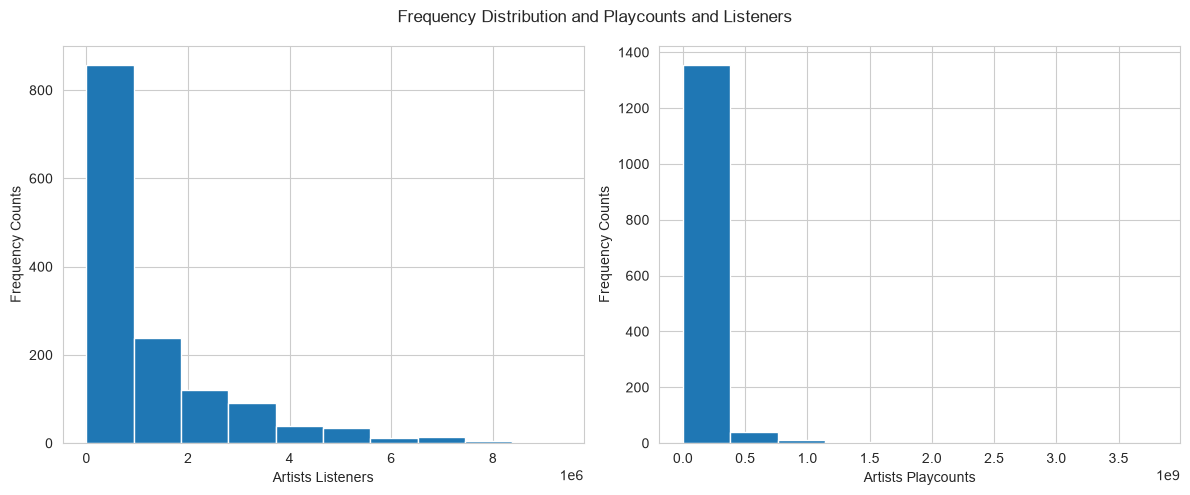

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

all_artists['artist_listeners'].hist(ax=ax[0])
all_artists['artist_playcount'].hist(ax=ax[1])


ax[0].set_xlabel('Artists Listeners')
ax[0].set_ylabel('Frequency Counts')
ax[1].set_xlabel('Artists Playcounts')
ax[1].set_ylabel('Frequency Counts')

plt.suptitle('Frequency Distribution and Playcounts and Listeners')
plt.tight_layout()

## Cleaning

In [8]:
repeated = {'hip-hop' : 'hip hop', 'rnb' : 'r&b', 'lofi' : 'lo-fi', 'kpop' : 'k-pop',
            'alt rock' : 'alternative rock'}
non_genre = {"american", "british", "uk", "male vocalists", "female vocalists", "philippines",
             "aaliyah", "usa", "us ", "canadian", "youtube", "united states"}

def _preprocess(col):

    def _clean(s):

        tokens = [t.strip().lower() for t in s.split(",") if t.strip()]
        tokens = [repeated.get(t, t) for t in tokens]
        return ", ".join(t for t in tokens if t not in non_genre)
    return col.fillna("").astype(str).map(_clean)
tokenizer = lambda s: [t.strip() for t in s.strip(",") if t.strip()]
all_artists[["tags", "similar_artists"]] = all_artists[["tags", "similar_artists"]].apply(_preprocess)

def _clean_tags(s):
    toks = [repeated.get(t, t) for t in (x.strip().lower() for x in s.split(",")) if t]
    seen, out = set(), []
    for t in toks:
        if t not in non_genre and t not in seen:
            seen.add(t); out.append(t)
    return ", ".join(out)

def _clean_sim(s):
    return ", ".join(x.strip().lower() for x in s.split(",") if x.strip())

all_artists["tags"] = all_artists["tags"].fillna("").astype(str).map(_clean_tags)
all_artists["similar_artists"] = all_artists["similar_artists"].fillna("").astype(str).map(_clean_sim)

tokenizer = lambda s: [t.strip() for t in s.split(",") if t.strip()]

all_artists.head()

,primary_artist_name,artist_listeners,artist_playcount,tags,similar_artists,source
0,(Hed) P.E.,150657,4410090,"rapcore, nu metal, crossover, g-punk, alternat...","(hed) planet earth, reveille, primer 55, coal ...",library
1,*NSYNC,2157048,32982790,"pop, boybands, 90s, dance, boy band, teen pop,...","jc chasez, backstreet boys, o-town, justin tim...",library
2,2 Chainz,1490344,27551890,"hip hop, rap, trap, dirty south, southern rap,...","young jeezy, lil' wayne, gucci mane, t.i., ric...",library
3,21 Savage,2407273,227824623,"trap, hip hop, rap, atlanta, southern hip hop,...","metro boomin, future, offset, travi$ scott, li...",library
4,2Pac,4312766,153016025,"rap, hip hop, gangsta rap, west coast rap, wes...","thug life, the notorious b.i.g., dr. dre, snoo...",library


In [24]:
all_artists.to_csv('all_artists.csv', index=False)

In [19]:
from scipy.sparse import save_npz

In [21]:
tag_vectorizer = TfidfVectorizer(tokenizer=tokenizer, token_pattern=None, lowercase=False,
                             sublinear_tf=True, min_df=2)

artists_vectorizer = TfidfVectorizer(tokenizer=tokenizer, token_pattern=None, lowercase=False,
                             sublinear_tf=True, min_df=2)

tags_vec = tag_vectorizer.fit_transform(all_artists['tags'])
similar_artists_vec = artists_vectorizer.fit_transform(all_artists['similar_artists'])

tags_similarities = cosine_similarity(tags_vec)
artist_similarities = cosine_similarity(similar_artists_vec)

combined_sims = normalize(hstack([1.0 * tags_vec, 0.5 * similar_artists_vec]).tocsr())
# combined_sims = cosine_similarity(combined_sims)

In [23]:
save_npz('feature_matrix.npz', combined_sims)

<Axes: ylabel='primary_artist_name'>

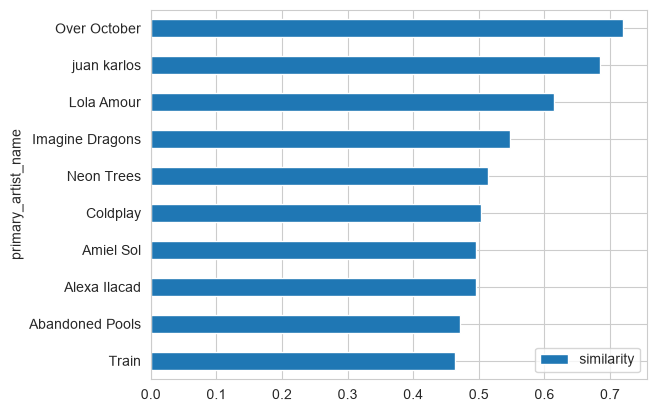

In [10]:
# helper functions for recommendations

vocabulary = np.array(tag_vectorizer.get_feature_names_out())
tags_sims = cosine_similarity(tags_vec.T)

def similar_artists(name: str, n: int = 10) -> pd.DataFrame:
    i = all_artists.index[all_artists['primary_artist_name'].str.lower() == name.lower()][0]
    order = np.argsort(-tags_similarities[i])
    order = order[order != i][:n]
    return (all_artists.iloc[order][['primary_artist_name', 'tags', 'source']].assign(similarity=tags_similarities[i][order].round(3)))

def artists_w_tags(tag: str, n: int = 10) -> pd.DataFrame:
    m = all_artists['tags'].map(lambda s: tag.lower() in tokenizer(s))
    return all_artists[m].nlargest(n, 'artist_listeners')[['primary_artist_name', 'tags', 'source']]

def related_tags(tag: str, n: int = 10) -> pd.Series:
    j = list(vocabulary).index(tag.lower())
    order = np.argsort(-tags_sims[j])
    order = order[order != j][:n]
    return pd.Series(tags_sims[j][order].round(3), index=pd.Index(vocabulary[order]).str.title())

# sample query of similar artist
sims = similar_artists("Zild")
sims = sims.set_index('primary_artist_name')[['similarity']].sort_values(by='similarity', ascending=True)
sims.plot(kind='barh')

In [11]:
artists_w_tags("alternative")

,primary_artist_name,tags,source
92,Coldplay,"rock, alternative, britpop, alternative rock, ...",library
375,Radiohead,"rock, alternative, alternative rock, indie, el...",library
327,Nirvana,"grunge, rock, alternative rock, alternative, 9...",library
382,Red Hot Chili Peppers,"rock, alternative rock, funk rock, alternative...",library
32,Arctic Monkeys,"indie rock, indie, alternative, rock, alternat...",library
257,Linkin Park,"nu metal, rock, alternative rock, alternative,...",library
1263,Gorillaz,"electronic, alternative, hip hop, rock, indie,...",candidate
285,Maroon 5,"pop rock, rock, pop, alternative, alternative ...",library
170,Green Day,"punk rock, rock, punk, pop punk, alternative, ...",library
314,Muse,"alternative rock, rock, progressive rock, alte...",library


In [12]:
related_tags("alternative")

Alternative Rock     0.766
Rock                 0.674
Indie                0.465
Indie Rock           0.430
Alternative Metal    0.385
Post-Grunge          0.365
Hard Rock            0.334
Nu Metal             0.318
Pop Rock             0.315
Grunge               0.293
dtype: float64

### Scoring Candidates against from my Library

In [13]:
is_lib = (all_artists['source'] == 'library').values

similarities = combined_sims[np.ix_(~is_lib, is_lib)] 
candidates = all_artists[~is_lib].copy()
candidates['score'] = np.sort(similarities, axis=1)[:, -10:].mean(axis=1)
top = candidates.sort_values("score", ascending=False).head(20)
top

,primary_artist_name,artist_listeners,artist_playcount,tags,similar_artists,source,score
896,10 Years,834357,19068003,"alternative rock, alternative metal, rock, har...","evans blue, chevelle, cold, seether, crossfade...",candidate,0.756246
733,Finger Eleven,1647804,24997444,"alternative rock, rock, hard rock, alternative...","trapt, thornley, our lady peace, 10 years, col...",candidate,0.752576
726,Depswa,69217,819722,"alternative metal, nu metal, alternative rock,...","lo-pro, five bolt main, onesidezero, edgewater...",candidate,0.729707
1190,Stone Temple Pilots,2598336,78990121,"grunge, alternative rock, rock, alternative, 9...","alice in chains, soundgarden, temple of the do...",candidate,0.661782
673,Jay Sean,1916086,21293357,"r&b, pop, soul, jay sean, desi, dance, hip hop","iyaz, sean kingston, jason derülo, ne-yo, shon...",candidate,0.649892
867,Seven Mary Three,400552,3276826,"alternative rock, grunge, rock, 90s, alternati...","candlebox, days of the new, better than ezra, ...",candidate,0.641291
975,Vedo,379528,4635782,"r&b, soul, pop, the voice","eric bellinger, jacquees, rini, jeremih, cean ...",candidate,0.633076
1171,Timbaland,3709541,67525790,"hip hop, r&b, rap, pop, timbaland, dance","timbaland & magoo, justin timberlake, keri hil...",candidate,0.622616
978,MoKenStef,270226,1850356,"r&b, 90s, soul, girl groups, pop, hip hop, urb...","702, kut klose, swv, ginuwine, brandy & monica...",candidate,0.619482
588,The Exies,426961,5608039,"alternative rock, post-grunge, rock, alternati...","smile empty soul, trustcompany, submersed, dee...",candidate,0.618107


In [14]:
lib_names = all_artists.loc[is_lib, 'primary_artist_name'].values
nearest = np.argsort(-similarities, axis=1)[:, :3]
candidates['listened_to'] = [', '.join(lib_names[i] for i in row) for row in nearest]

top = candidates.sort_values('score', ascending=False).head(20)
top[['primary_artist_name', 'score', 'artist_listeners', 'listened_to']]

,primary_artist_name,score,artist_listeners,listened_to
896,10 Years,0.756246,834357,"Staind, Three Days Grace, Chevelle"
733,Finger Eleven,0.752576,1647804,"Staind, Chevelle, Three Days Grace"
726,Depswa,0.729707,69217,"TRUSTcompany, Korn, Element Eighty"
1190,Stone Temple Pilots,0.661782,2598336,"Audioslave, Nickelback, Foo Fighters"
673,Jay Sean,0.649892,1916086,"Justin Timberlake, USHER, Jessie J"
867,Seven Mary Three,0.641291,400552,"Our Lady Peace, Local H, Creed"
975,Vedo,0.633076,379528,"Luke Chiang, Elmiene, DENȲ"
1171,Timbaland,0.622616,3709541,"Chris Brown, USHER, will.i.am"
978,MoKenStef,0.619482,270226,"702, Kut Klose, Brandy"
588,The Exies,0.618107,426961,"Cold, Chevelle, Staind"


In [15]:
# popluarity bias check
print("Median Listeners - Top 20:", top.artist_listeners.median())
print("Median Listeners - All Candidates:", candidates.artist_listeners.median())

pop_top = candidates.nlargest(20, 'artist_listeners')
print("Median Listeners - Most-Popular Top 20:", pop_top.artist_listeners.median())

Median Listeners - Top 20: 413756.5
Median Listeners - All Candidates: 294842.0
Median Listeners - Most-Popular Top 20: 5017649.5


In [16]:
library_idx = np.where(is_lib)[0]
candidate_idx = np.where(~is_lib)[0]

popularity = all_artists['artist_listeners'].values
rows = []

for seed in range(10):

    rng = np.random.default_rng(seed)
    # hidden lib artists
    test = rng.choice(library_idx, size=int(0.2 * len(library_idx)), replace=False)
    train = np.setdiff1d(library_idx, test)
    pooling = np.concatenate([candidate_idx, test])
    y = np.r_[np.zeros(len(candidate_idx)), np.ones(len(test))]

    s = combined_sims[np.ix_(pooling, train)]
    scores = {
        'model' : np.sort(s, axis=1)[:, -10:].mean(axis=1),
        'random' : rng.random(len(pooling)),
        'popular' : popularity[pooling].astype(float)
    }

    for name, s in scores.items():
        top20 = np.argsort(-s)[:20]
        rows.append((seed, name, roc_auc_score(y, s), y[top20].mean()))

res = pd.DataFrame(rows, columns=['seed', 'method', 'auc', 'precision@20'])
print(res.groupby('method')[['auc', 'precision@20']].agg(['mean', 'std']).round(3))
print("Base Rate (Random Precision):", round(len(test) / len(pooling), 3))

           auc        precision@20       
          mean    std         mean    std
method                                   
model    0.679  0.029        0.380  0.098
popular  0.751  0.022        0.445  0.112
random   0.503  0.023        0.130  0.089
Base Rate (Random Precision): 0.121


In [17]:
def holdout_by_pop(sim, k=10, seeds=range(10), n_bins=3):
    out = []
    for seed in seeds:
        rng = np.random.default_rng(seed)
        test  = rng.choice(library_idx, size=int(0.2 * len(library_idx)), replace=False)
        train = np.setdiff1d(library_idx, test)
        pool  = np.concatenate([candidate_idx, test])
        y = np.r_[np.zeros(len(candidate_idx)), np.ones(len(test))]
        model = np.sort(sim[np.ix_(pool, train)], axis=1)[:, -k:].mean(axis=1)
        band = pd.qcut(np.log10(popularity[pool].astype(float) + 1), n_bins, labels=False, duplicates='drop')
        for b in np.unique(band):
            m = band == b
            if y[m].sum() >= 5 and y[m].sum() < m.sum():
                out.append((seed, b, roc_auc_score(y[m], model[m])))
    return pd.DataFrame(out, columns=['seed', 'pop_band', 'auc']).groupby('pop_band').auc.agg(['mean', 'std'])

print(holdout_by_pop(tags_similarities))

              mean       std
pop_band                    
0         0.647452  0.092059
1         0.548377  0.039503
2         0.622674  0.025316


In [18]:
combined_sims

array([[1.        , 0.        , 0.        , ..., 0.03757627, 0.        ,
        0.        ],
       [0.        , 1.        , 0.        , ..., 0.02619066, 0.        ,
        0.02794773],
       [0.        , 0.        , 1.        , ..., 0.04010818, 0.        ,
        0.        ],
       ...,
       [0.03757627, 0.02619066, 0.04010818, ..., 1.        , 0.        ,
        0.03580179],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.02794773, 0.        , ..., 0.03580179, 0.        ,
        1.        ]], shape=(1413, 1413))